In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/customer_churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 7043
Number of Columns: 21


In [5]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [9]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
print(df['TotalCharges'].dtype)

print("Blank values:", (df['TotalCharges'].str.strip() == '').sum())

print(df['TotalCharges'].head(10))

str
Blank values: 11
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str


In [13]:
print(df['TotalCharges'].dtype)

str


In [14]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [15]:
print(df['TotalCharges'].dtype)

float64


In [16]:
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())


Missing TotalCharges: 11


In [17]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [20]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [21]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [22]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 11


In [23]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [24]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [25]:
df.isnull().sum().sum()

np.int64(11)

In [26]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [27]:
df[df['TotalCharges'].isnull()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [28]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [29]:
df.isnull().sum().sum()

np.int64(0)

In [30]:
missing_data = df[df['TotalCharges'].isnull()]

print("Number of missing records:", len(missing_data))

print("Are all customers having zero tenure?",
      (missing_data['tenure'] == 0).all())

Number of missing records: 0
Are all customers having zero tenure? True


In [31]:
raw_df = pd.read_csv("../dataset/customer_churn.csv")

raw_df['TotalCharges'] = pd.to_numeric(
    raw_df['TotalCharges'],
    errors='coerce'
)

missing_data = raw_df[raw_df['TotalCharges'].isnull()]

print("Missing records:", len(missing_data))

print("All have zero tenure:",
      (missing_data['tenure'] == 0).all())

Missing records: 11
All have zero tenure: True


In [32]:
df.to_csv("../dataset/cleaned_customer_churn.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [33]:
print("Remaining missing values:", df.isnull().sum().sum())

print("Duplicate records:", df.duplicated().sum())

print("Total records:", df.shape[0])

Remaining missing values: 0
Duplicate records: 0
Total records: 7043


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
sns.set_style("whitegrid")

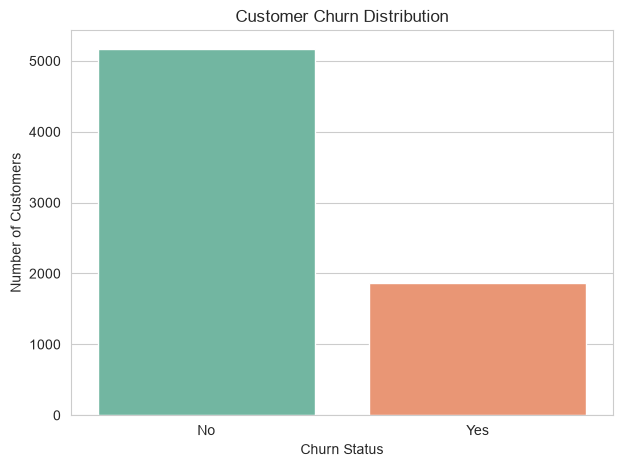

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [37]:
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage.round(2))

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


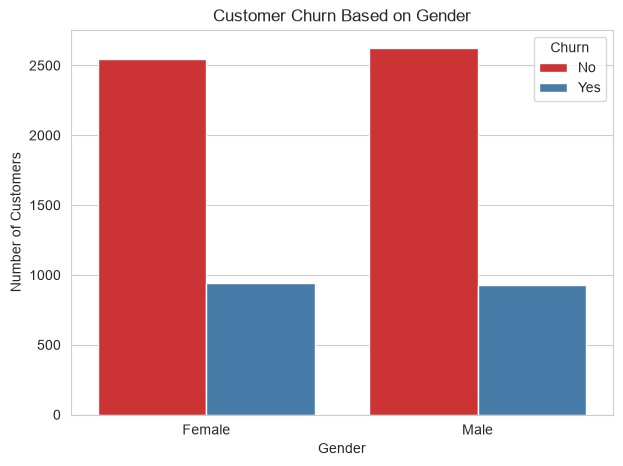

In [38]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='Churn',
    palette='Set1'
)

plt.title('Customer Churn Based on Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

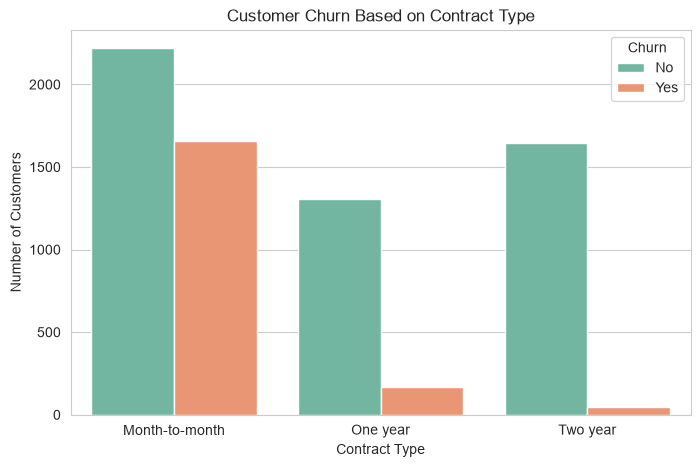

In [39]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn Based on Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

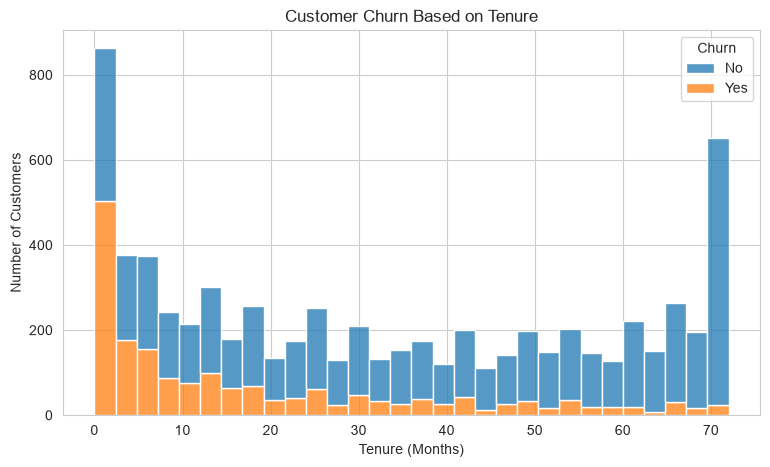

In [40]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    multiple='stack',
    bins=30
)

plt.title('Customer Churn Based on Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

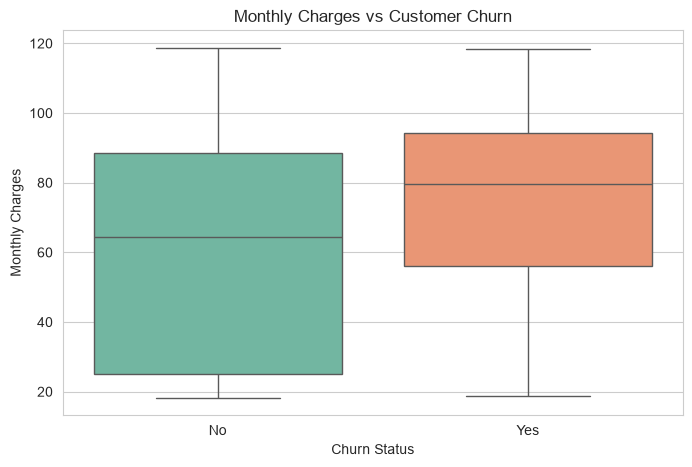

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')

plt.show()

In [42]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


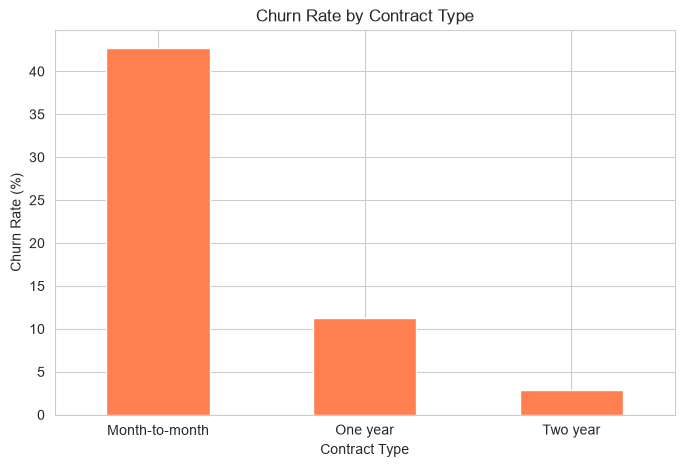

In [43]:
contract_churn['Yes'].plot(
    kind='bar',
    figsize=(8, 5),
    color='coral'
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [44]:
gender_churn = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

print(gender_churn.round(2))

Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


In [45]:
df = df.drop('customerID', axis=1)

print("CustomerID column removed successfully!")

CustomerID column removed successfully!


In [46]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [47]:
X = df.drop('Churn', axis=1)

y = df['Churn']

In [48]:
print("Features shape:", X.shape)

print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [49]:
y = y.map({
    'No': 0,
    'Yes': 1
})

In [50]:
print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [51]:
categorical_cols = X.select_dtypes(
    include=['object', 'str']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [54]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


In [55]:
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_cols),

        ('numerical',
         StandardScaler(),
         numerical_cols)
    ]
)

In [56]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [57]:
print("Original Training Shape:", X_train.shape)

print("Processed Training Shape:", X_train_processed.shape)

print("Original Testing Shape:", X_test.shape)

print("Processed Testing Shape:", X_test_processed.shape)

Original Training Shape: (5634, 19)
Processed Training Shape: (5634, 45)
Original Testing Shape: (1409, 19)
Processed Testing Shape: (1409, 45)


In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Machine Learning algorithms imported successfully!")

Machine Learning algorithms imported successfully!


In [59]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [60]:
y_pred_log = log_model.predict(X_test_processed)

print("Predictions generated successfully!")

Predictions generated successfully!


In [61]:
print("Actual Values:", y_test.values[:10])

print("Predicted Values:", y_pred_log[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 1]
Predicted Values: [0 1 0 0 0 1 0 0 0 0]


In [62]:
accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.55 %


In [63]:
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



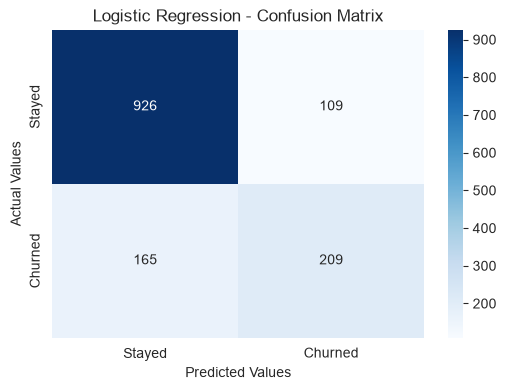

In [64]:
cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [65]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred_log) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, y_pred_log) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, y_pred_log) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, y_pred_log) * 100, 2), "%")

Accuracy: 80.55 %
Precision: 65.72 %
Recall: 55.88 %
F1 Score: 60.4 %


In [66]:
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [67]:
y_pred_dt = dt_model.predict(X_test_processed)

print("Decision Tree predictions generated!")

Decision Tree predictions generated!


In [68]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 79.84 %


In [69]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



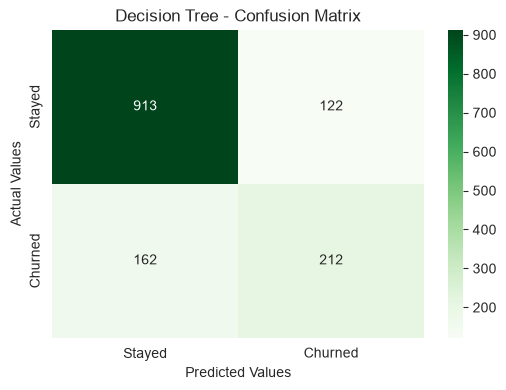

In [70]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [71]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [72]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [73]:
y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest predictions generated successfully!")

Random Forest predictions generated successfully!


In [74]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 78.78 %


In [75]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



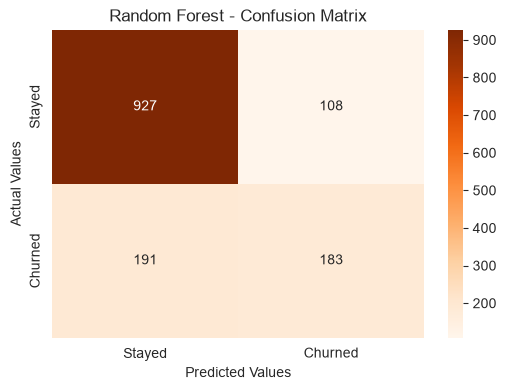

In [76]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf
}

results = []

for name, predictions in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.set_index('Model')

print(comparison_df.round(4))

                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression    0.8055     0.6572  0.5588    0.6040
Decision Tree          0.7984     0.6347  0.5668    0.5989
Random Forest          0.7878     0.6289  0.4893    0.5504


In [78]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(15))

                                        Feature  Importance
44                      numerical__TotalCharges    0.165771
43                    numerical__MonthlyCharges    0.137849
42                            numerical__tenure    0.133571
32         categorical__Contract_Month-to-month    0.048242
14               categorical__OnlineSecurity_No    0.032442
39  categorical__PaymentMethod_Electronic check    0.030610
23                  categorical__TechSupport_No    0.025750
12     categorical__InternetService_Fiber optic    0.023673
41                     numerical__SeniorCitizen    0.019807
34               categorical__Contract_Two year    0.019629
0                    categorical__gender_Female    0.017788
1                      categorical__gender_Male    0.017740
17                 categorical__OnlineBackup_No    0.017347
35             categorical__PaperlessBilling_No    0.015490
36            categorical__PaperlessBilling_Yes    0.015076


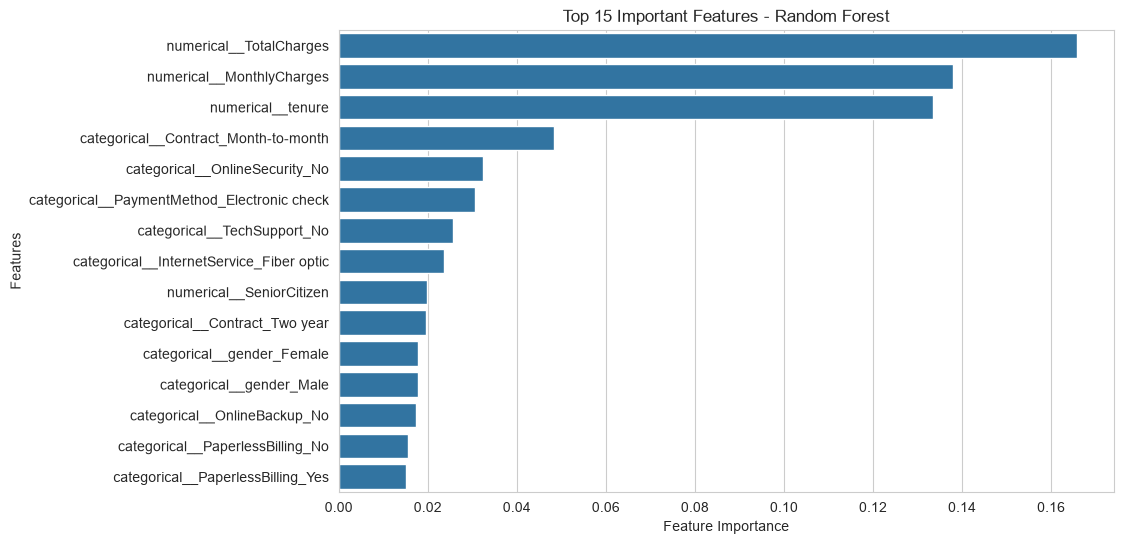

In [79]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.show()

In [80]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [81]:
log_params = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced']
}

grid_log = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    log_params,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_log.fit(X_train_processed, y_train)

print("Best Parameters:", grid_log.best_params_)
print("Best Cross-validation Recall:", grid_log.best_score_)

Best Parameters: {'C': 1, 'class_weight': 'balanced'}
Best Cross-validation Recall: 0.8040133779264215


In [82]:
best_log_model = grid_log.best_estimator_

y_pred_tuned_log = best_log_model.predict(X_test_processed)

print(classification_report(y_test, y_pred_tuned_log))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



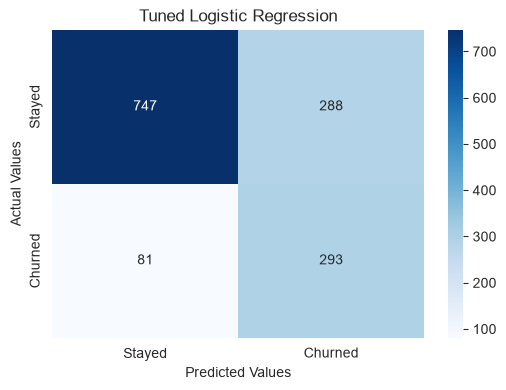

In [83]:
cm = confusion_matrix(y_test, y_pred_tuned_log)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Tuned Logistic Regression')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [84]:
dt_params = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}

In [85]:
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_dt.fit(X_train_processed, y_train)

print("Best Parameters:", grid_dt.best_params_)

print("Best Cross-validation Recall:", grid_dt.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-validation Recall: 0.788628762541806


In [86]:
best_dt_model = grid_dt.best_estimator_

y_pred_tuned_dt = best_dt_model.predict(X_test_processed)

print(classification_report(y_test, y_pred_tuned_dt))

              precision    recall  f1-score   support

           0       0.89      0.73      0.80      1035
           1       0.50      0.76      0.60       374

    accuracy                           0.74      1409
   macro avg       0.70      0.74      0.70      1409
weighted avg       0.79      0.74      0.75      1409



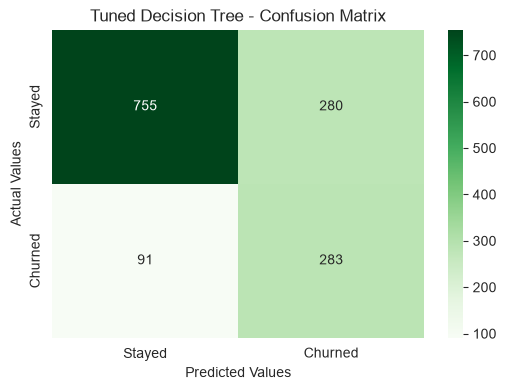

In [87]:
cm_dt = confusion_matrix(y_test, y_pred_tuned_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Tuned Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [88]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': [None, 'balanced']
}

In [89]:
grid_rf = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    rf_params,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_rf.fit(X_train_processed, y_train)

print("Best Parameters:", grid_rf.best_params_)

print("Best Cross-validation Recall:", grid_rf.best_score_)

Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-validation Recall: 0.7632107023411372


In [90]:
best_rf_model = grid_rf.best_estimator_

y_pred_tuned_rf = best_rf_model.predict(X_test_processed)

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [91]:
print(classification_report(y_test, y_pred_tuned_rf))

              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



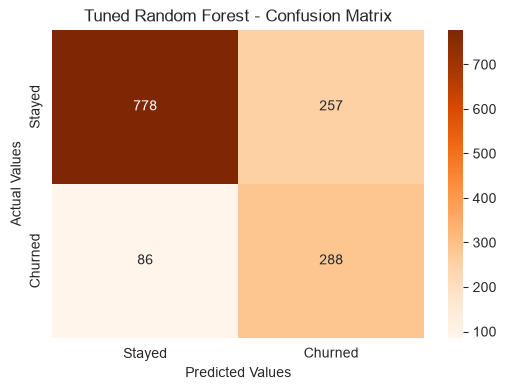

In [92]:
cm_rf = confusion_matrix(y_test, y_pred_tuned_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Stayed', 'Churned'],
    yticklabels=['Stayed', 'Churned']
)

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [93]:
final_models = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Tuned Logistic Regression': y_pred_tuned_log,
    'Tuned Decision Tree': y_pred_tuned_dt,
    'Tuned Random Forest': y_pred_tuned_rf
}

final_results = []

for name, predictions in final_models.items():

    final_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(final_results)

final_comparison = final_comparison.sort_values(
    by='F1 Score',
    ascending=False
)

print(final_comparison.round(4))

                       Model  Accuracy  Precision  Recall  F1 Score
5        Tuned Random Forest    0.7566     0.5284  0.7701    0.6268
3  Tuned Logistic Regression    0.7381     0.5043  0.7834    0.6136
4        Tuned Decision Tree    0.7367     0.5027  0.7567    0.6041
0        Logistic Regression    0.8055     0.6572  0.5588    0.6040
1              Decision Tree    0.7984     0.6347  0.5668    0.5989
2              Random Forest    0.7878     0.6289  0.4893    0.5504


<Figure size 1200x600 with 0 Axes>

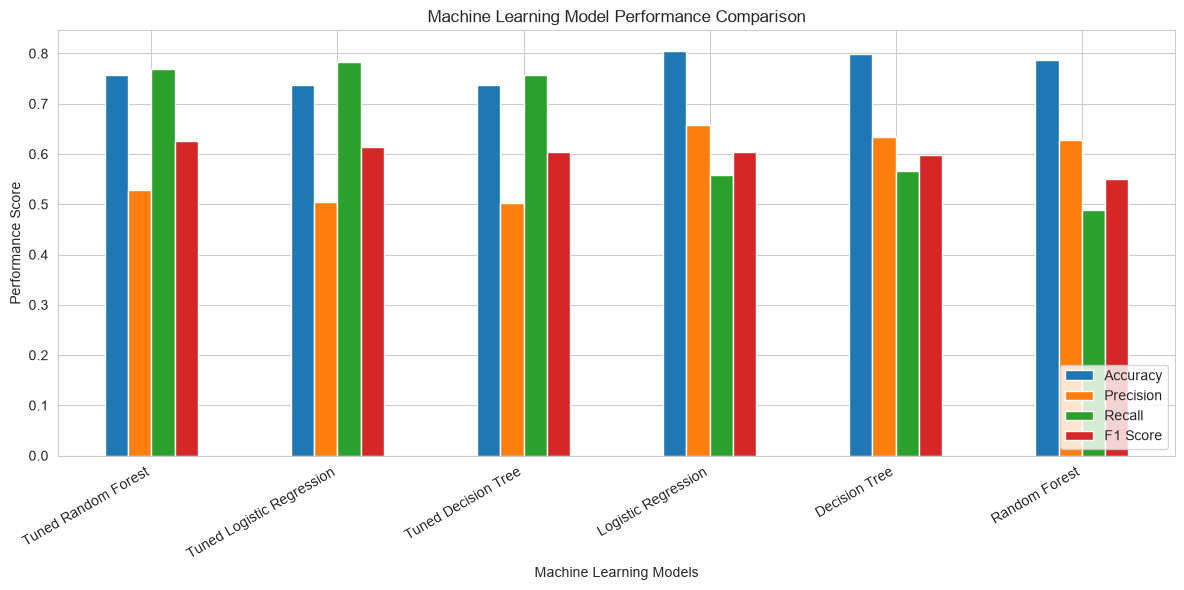

In [94]:
plt.figure(figsize=(12, 6))

final_comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(12, 6))

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Models')

plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [95]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [96]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(best_rf_model, '../models/random_forest_model.pkl')

joblib.dump(preprocessor, '../models/preprocessor.pkl')

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
